In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files

import calendar

In [ ]:
uploaded = files.upload()

Saving retail_sales.csv to retail_sales.csv


In [ ]:
retail = pd.read_csv('retail_sales.csv')
retail.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


**Basic Dataset Info**

In [ ]:
retail.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

In [ ]:
retail.shape

(1000, 9)

In [ ]:

print(f"DATATYPES:\n{retail.dtypes}")

DATATYPES:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object


In [ ]:
retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


<class 'pandas.core.frame.DataFrame'> ==> Object is a pandas dataframe

RangeIndex: 1000 entries, 0 to 999 ==> The DataFrame has 1000 rows. The row index goes from 0 to 999.

Data columns (total 9 columns): ==> 9 columns

**Changing Date datatype to 'datetime' datatype**

In [ ]:
retail['Date'] = pd.to_datetime(retail['Date'])
print(f"Date Datatype: {retail.dtypes['Date']}")

Date Datatype: datetime64[ns]


**Check for missing values**

In [ ]:
retail.isnull().sum()

,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


In [ ]:
print(f"Number of Customers: {retail['Customer ID'].nunique()}")

Number of Customers: 1000


In [ ]:
print(f"Average age of customers: {retail['Age'].mean().round(2)}")

Average age of customers: 41.39


In [ ]:
# Renaming for ease of use
retail.rename(columns={'Product Category':'Category'}, inplace=True)

# Categories present
print(retail['Category'].unique())

['Beauty' 'Clothing' 'Electronics']


# Category-wise Transaction Volume Analysis

In [ ]:
grouping = retail.groupby('Category')['Transaction ID'].count()
print(grouping)

Category
Beauty         307
Clothing       351
Electronics    342
Name: Transaction ID, dtype: int64


**Representation using Pie Chart**

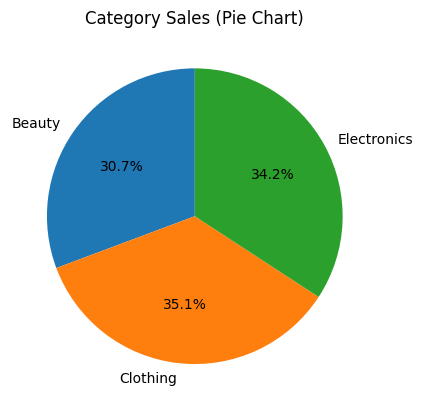

In [ ]:
plt.pie(grouping.values, labels=grouping.index, autopct='%1.1f%%', startangle=90)
plt.title('Category Sales (Pie Chart)')
plt.show()

# Average Basket Size per Transaction




In [ ]:
print(f"Average quantity purchased per transactions: {retail['Quantity'].mean()}")

Average quantity purchased per transactions: 2.514


# Customer Spend Metrics (Max, Min, Avg per Transaction)


In [ ]:
print("What is the maximum, minimum, and average Total Amount spent in a single transaction?")
maximum= retail['Total Amount'].max()
minimum = retail['Total Amount'].min()
average = retail['Total Amount'].mean()
print(f"The maximum Amount spent in a single transaction is {maximum}")
print(f"The minimum Amount spent in a single transaction is {minimum}")
print(f"The average Amount spent in a single transaction is {average}")

What is the maximum, minimum, and average Total Amount spent in a single transaction?
The maximum Amount spent in a single transaction is 2000
The minimum Amount spent in a single transaction is 25
The average Amount spent in a single transaction is 456.0


# QUESTION 1 # Sales Trend Analysis Over Time

In [ ]:

unique_dates = retail['Date'].dt.date.nunique()
print(f"Number of unique dates: {unique_dates}")

daily_sales = retail.groupby(retail['Date'].dt.date)['Total Amount'].sum()
print(daily_sales.head())


Number of unique dates: 345
Date
2023-01-01    3600
2023-01-02    1765
2023-01-03     600
2023-01-04    1240
2023-01-05    1100
Name: Total Amount, dtype: int64


In [ ]:
monthly_sales = retail.groupby(retail['Date'].dt.month)['Total Amount'].sum()
print(monthly_sales)

Date
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64


**Representing Monthly Sales using Line Chart**

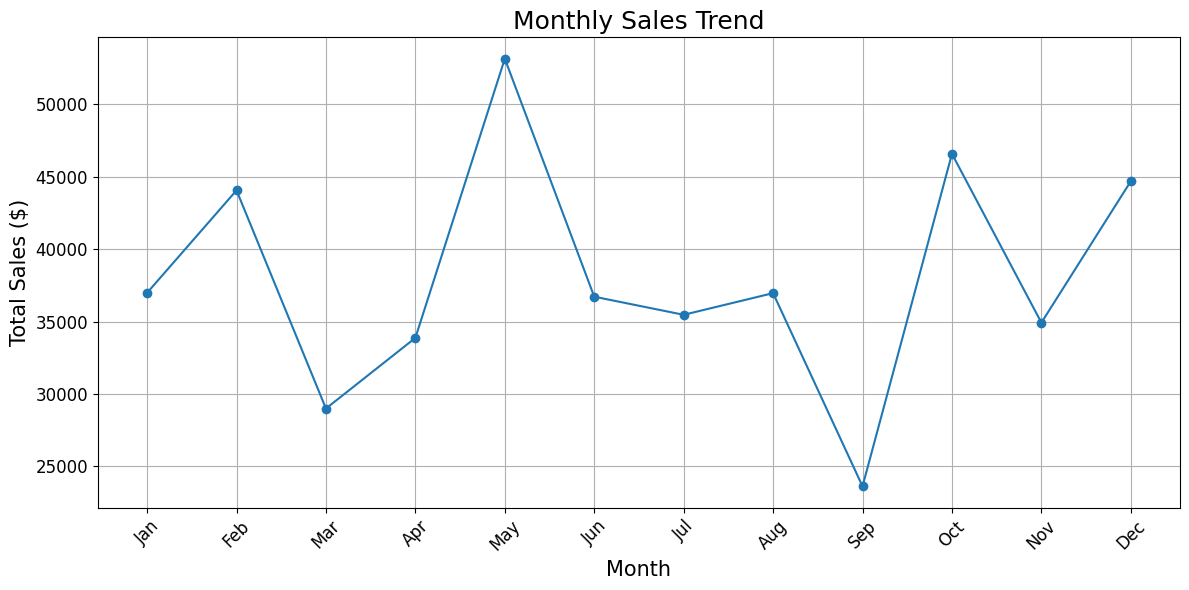

In [ ]:

monthly_sales.index = monthly_sales.index.map(lambda x: calendar.month_abbr[x])

plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o', linestyle='-')

plt.title('Monthly Sales Trend', fontsize=18)
plt.xlabel('Month', fontsize=15)
plt.ylabel('Total Sales ($)', fontsize=15)
plt.xticks(rotation=45, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()




# QUESTION 2 # Revenue Contribution by Product Category

In [ ]:
highest_revenue = retail.groupby('Category')['Total Amount'].sum().sort_values(ascending=False)
print(highest_revenue)


Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


**Representation using Pie Chart**

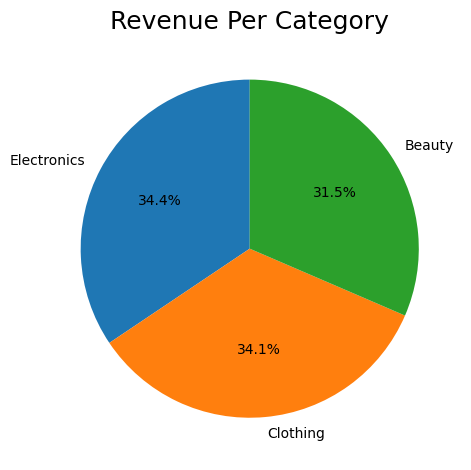

In [ ]:
plt.pie(highest_revenue.values, labels=highest_revenue.index, autopct="%1.1f%%", startangle=90)
plt.title("Revenue Per Category", fontsize=18)
plt.tight_layout()
plt.show()

# Top 10 High-Value Customers (RFM: Monetary Value)

In [ ]:
top_customers = retail.groupby('Customer ID')['Total Amount'].sum().sort_values(ascending=False).head(10)
print(top_customers.index)



Index(['CUST015', 'CUST412', 'CUST970', 'CUST547', 'CUST281', 'CUST416',
       'CUST420', 'CUST927', 'CUST447', 'CUST342'],
      dtype='object', name='Customer ID')


# QUESTION 3 # Age Distribution Histogram

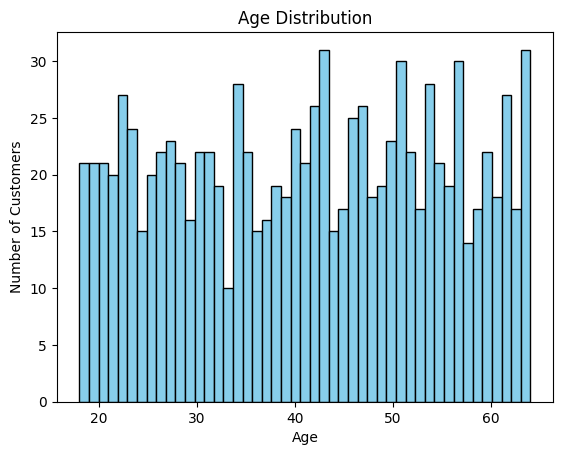

In [ ]:
plt.hist(retail['Age'], bins=47, color='skyblue', edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()



# QUESTION 4 # Gender-Based Spending Analysis

In [ ]:
gender_counts = retail['Gender'].value_counts()
print(f"Distribution of genders in the dataset? (Male vs Female count): \n{gender_counts} ")

Distribution of genders in the dataset? (Male vs Female count): 
Gender
Female    510
Male      490
Name: count, dtype: int64 


In [ ]:
gender_spend = retail.groupby('Gender')['Total Amount'].sum().sort_values(ascending=False)
print(gender_spend)


Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [ ]:
avg_spending = gender_spend / gender_counts
print(f"Average Spending per Customer by Gender: {avg_spending}")


Average Spending per Customer by Gender: Gender
Female    456.549020
Male      455.428571
dtype: float64


In [ ]:
gender_df = pd.DataFrame({
    'Population': gender_counts,
    'Total Spending': avg_spending
})

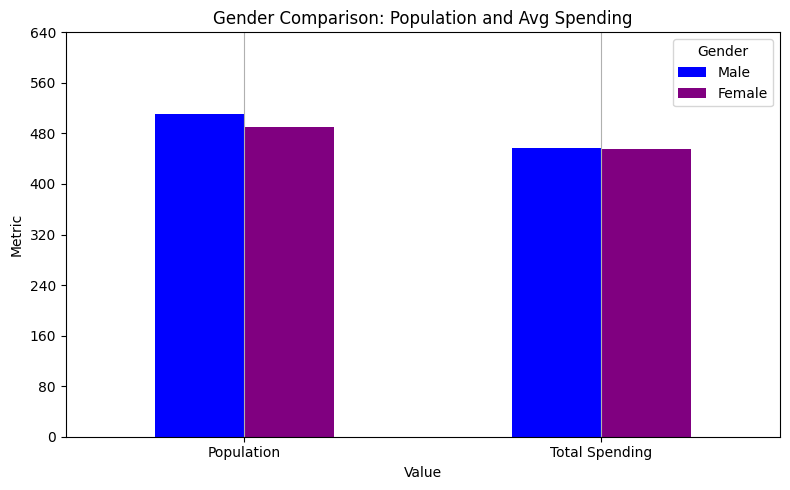

In [ ]:
gender_T = gender_df.T
gender_T.plot(kind='bar', figsize=(8, 5), color=['blue', 'purple'])  # Male, Female

# Customize
plt.title('Gender Comparison: Population and Avg Spending')
plt.xlabel('Value')
plt.ylabel('Metric')
plt.legend(title='Gender', labels=['Male', 'Female'])  # Ensures proper label order
plt.grid(axis='x')
plt.yticks(np.arange(0, 650, 80))

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

/tmp/ipython-input-3297488460.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=retail, x='Gender', y='Total Amount', palette={'Male': 'skyblue', 'Female': 'lightpink'})


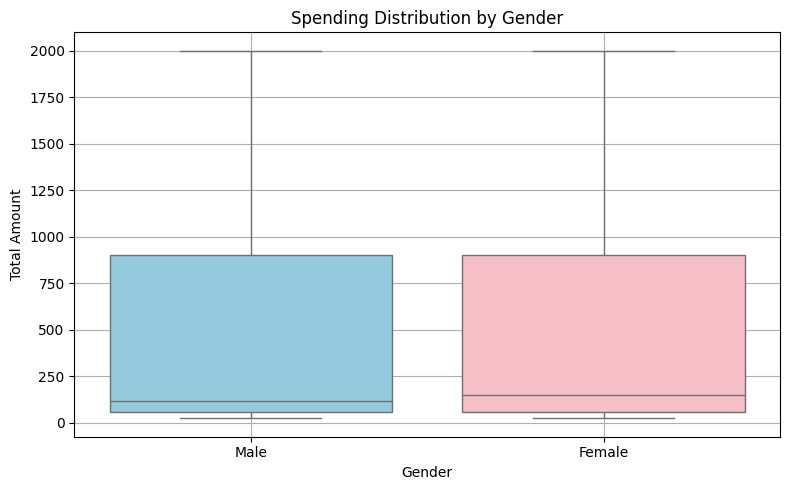

In [ ]:

plt.figure(figsize=(8, 5))
sns.boxplot(data=retail, x='Gender', y='Total Amount', palette={'Male': 'skyblue', 'Female': 'lightpink'})
plt.title('Spending Distribution by Gender')
plt.grid(True)
plt.tight_layout()
plt.show()

# QUESTION 5 # Age Group Purchasing Behavior Analysis

In [ ]:
bins = [17, 25, 35, 45, 55, 65]
labels = ['18–25', '26–35', '36–45', '46–55', '56–65']

retail['Age Group'] = pd.cut(retail['Age'], bins=bins, labels=labels)

age_spending = retail.groupby('Age Group')['Total Amount'].sum()
print(age_spending)


Age Group
18–25     84550
26–35     98480
36–45     91870
46–55    100690
56–65     80410
Name: Total Amount, dtype: int64


/tmp/ipython-input-2167640814.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_spending = retail.groupby('Age Group')['Total Amount'].sum()


In [ ]:
# Count of unique customers in each age group
age_customers = retail.groupby('Age Group')['Customer ID'].nunique()
print("Number of Customers in Each ",end="")
print(age_customers)

# Average spending per customer in each age group
avg_age_spending = age_spending / age_customers
print("\nAverage Spending of Each ", end="")
print(avg_age_spending.round(2))


Number of Customers in Each Age Group
18–25    169
26–35    205
36–45    202
46–55    229
56–65    195
Name: Customer ID, dtype: int64

Average Spending of Each Age Group
18–25    500.30
26–35    480.39
36–45    454.80
46–55    439.69
56–65    412.36
dtype: float64


/tmp/ipython-input-1422075741.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_customers = retail.groupby('Age Group')['Customer ID'].nunique()


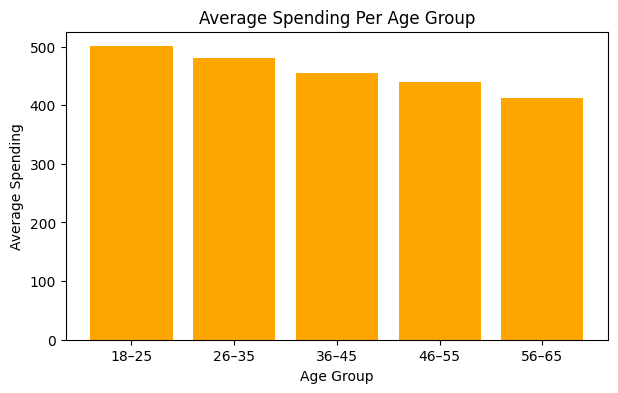

In [ ]:
plt.figure(figsize=(7, 4))
plt.bar(avg_age_spending.index, avg_age_spending.values, color='orange')
plt.title('Average Spending Per Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Spending')
plt.show()

In [ ]:
# Mode of Category per Age Group
age_category_mode = retail.groupby('Age Group')['Category'].agg(lambda x: x.mode().iloc[0])
print(age_category_mode)



Age Group
18–25         Beauty
26–35       Clothing
36–45       Clothing
46–55    Electronics
56–65       Clothing
Name: Category, dtype: object


/tmp/ipython-input-24589873.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_category_mode = retail.groupby('Age Group')['Category'].agg(lambda x: x.mode().iloc[0])


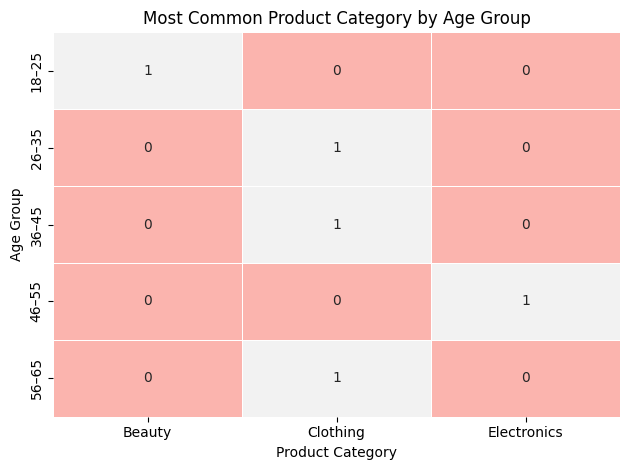

In [ ]:
#age_category = pd.series(age_category_mode)

# Create one-hot encoded DataFrame
df_heat = pd.get_dummies(age_category_mode)

# Plot heatmap
sns.heatmap(df_heat, annot=True, cbar=False, cmap='Pastel1', linewidths=0.5)
plt.title('Most Common Product Category by Age Group')
plt.xlabel('Product Category')
plt.ylabel('Age Group')
plt.tight_layout()
plt.show()

/tmp/ipython-input-1002099409.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heat_data = retail.pivot_table(index='Age Group', columns='Category',


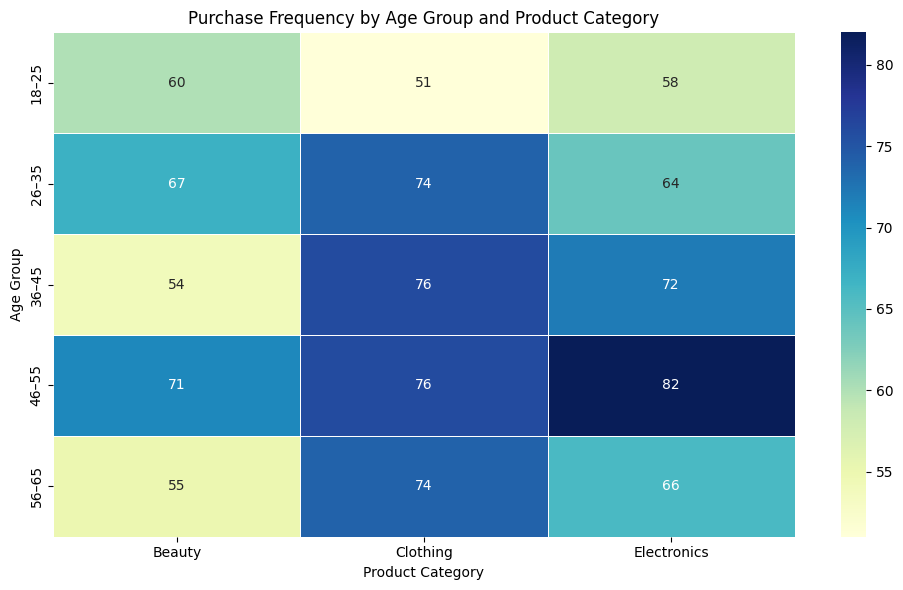

In [ ]:
heat_data = retail.pivot_table(index='Age Group', columns='Category',
                              values='Transaction ID', aggfunc='count', fill_value=0)

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(heat_data, annot=True, fmt='d', cmap='YlGnBu', linewidths=0.5)
plt.title('Purchase Frequency by Age Group and Product Category')
plt.xlabel('Product Category')
plt.ylabel('Age Group')
plt.tight_layout()
plt.show()

# Quantity Sold per Product Category

In [ ]:
avg_quantity = retail.groupby('Category')['Quantity'].count()
print(avg_quantity)


Category
Beauty         307
Clothing       351
Electronics    342
Name: Quantity, dtype: int64


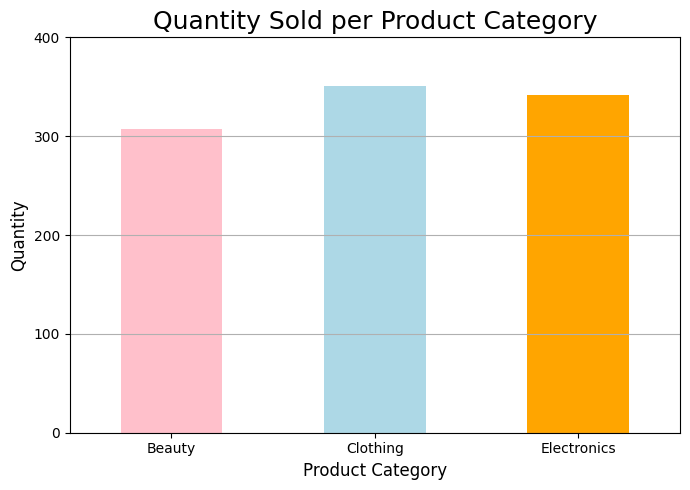

In [ ]:
avg_quantity.plot(kind='bar', color=['pink', 'lightblue', 'orange'], figsize=(7,5))

plt.title('Quantity Sold per Product Category', fontsize=18)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Quantity', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()

plt.yticks(np.arange(0, 401, 100))

plt.show()

# Total Revenue by Day-of-Week Analysis

In [ ]:
# Make sure 'Date' is datetime type
retail['Date'] = pd.to_datetime(retail['Date'])

# Extract day of the week as a name (Monday, Tuesday, etc.)
retail['DayOfWeek'] = retail['Date'].dt.day_name()

# Group by day of the week and sum sales
sales_by_day = retail.groupby('DayOfWeek')['Total Amount'].sum()

# To have days in calendar order, you can reindex:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sales_by_day = sales_by_day.reindex(days_order)

print(sales_by_day)

# Find the day with max sales
best_day = sales_by_day.idxmax()
best_sales = sales_by_day.max()

print(f"Day with highest sales: {best_day} (${best_sales:.2f})")


DayOfWeek
Monday       70250
Tuesday      69440
Wednesday    58770
Thursday     53835
Friday       66290
Saturday     78815
Sunday       58600
Name: Total Amount, dtype: int64
Day with highest sales: Saturday ($78815.00)


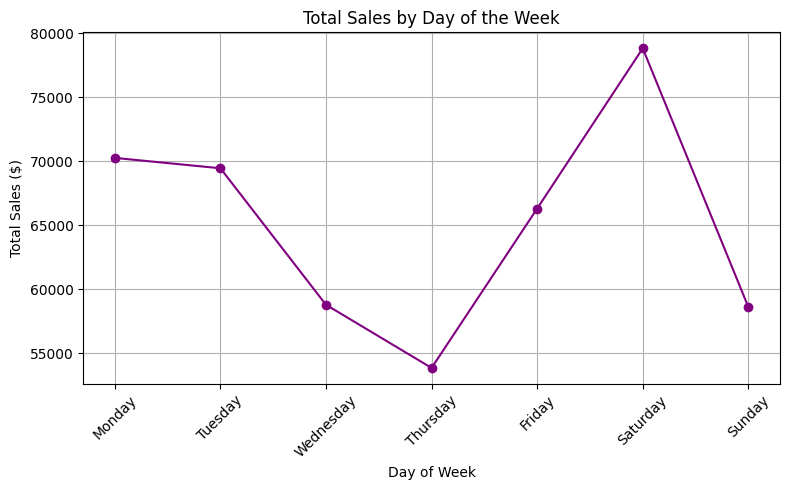

In [ ]:

plt.figure(figsize=(8,5))
sales_by_day.plot(kind='line', marker='o', linestyle='-', color='purple')

plt.title('Total Sales by Day of the Week')
plt.xlabel('Day of Week')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Count how many purchases of each category by each gender
gender_category = retail.groupby(['Category', 'Gender'])['Transaction ID'].count().unstack(fill_value=0)

print(gender_category)



Gender       Female  Male
Category                 
Beauty          166   141
Clothing        174   177
Electronics     170   172



# Gender Distribution by Product Category

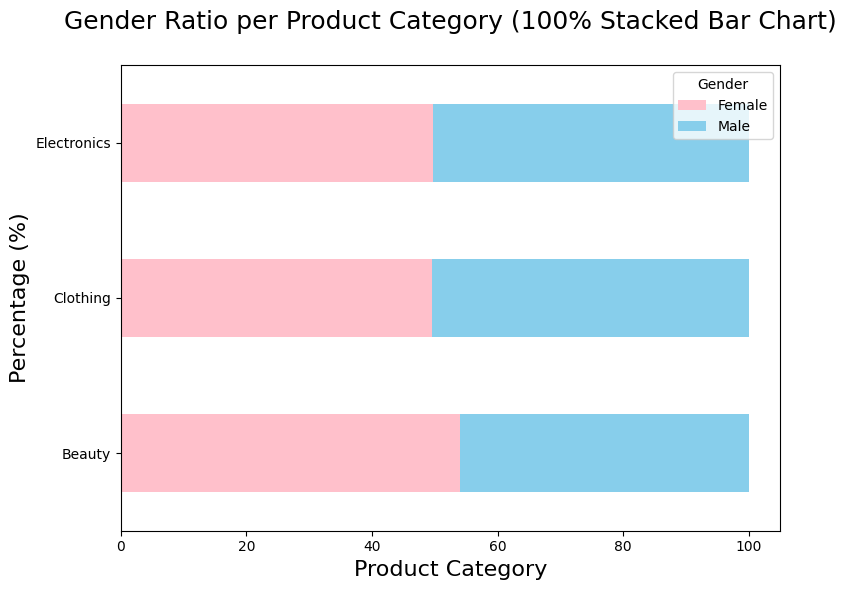

In [ ]:
# Convert counts to percentages
gender_category_percent = gender_category.div(gender_category.sum(axis=1), axis=0) * 100

# Plot 100% stacked horizontal bar chart
gender_category_percent.plot(kind='barh', stacked=True, figsize=(8,6), color=['pink','skyblue'])

plt.title('Gender Ratio per Product Category (100% Stacked Bar Chart)\n', fontsize=18)
plt.xlabel('Product Category', fontsize=16)
plt.ylabel('Percentage (%)', fontsize=16)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

# Price Distribution Across Product Category

In [ ]:
category_price = retail.groupby('Category')['Price per Unit'].mean()
print(category_price)


Category
Beauty         184.055375
Clothing       174.287749
Electronics    181.900585
Name: Price per Unit, dtype: float64


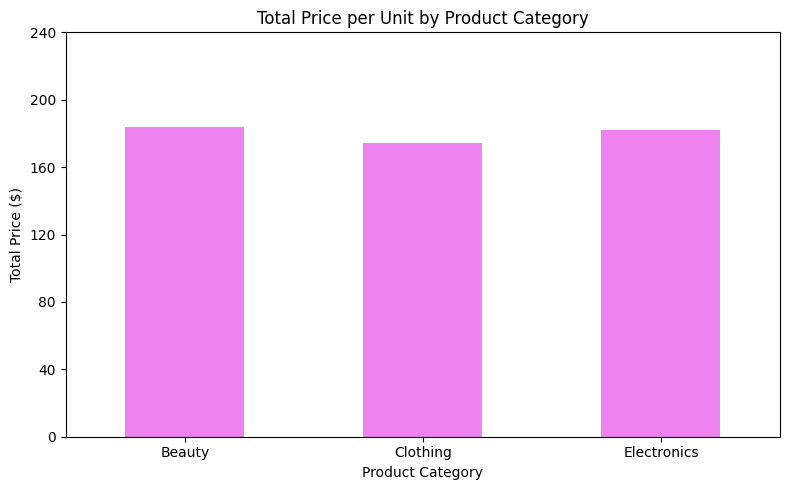

In [ ]:
category_price.plot(kind='bar', figsize=(8,5), color='violet')
plt.title('Total Price per Unit by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Price ($)')
plt.xticks(rotation=0)
plt.yticks(np.arange(0, 250, 40))
plt.tight_layout()
plt.show()

# Price–Quantity Relationship

In [ ]:
quantity_price = retail.groupby('Quantity')['Price per Unit'].mean()
print(quantity_price)


Quantity
1    177.094862
2    166.769547
3    199.564315
4    176.673004
Name: Price per Unit, dtype: float64


# Quantity vs. Total Spending Relationship

In [ ]:
quantity_price = retail.groupby('Quantity')['Total Amount'].mean()
print(quantity_price)


Quantity
1    177.094862
2    333.539095
3    598.692946
4    706.692015
Name: Total Amount, dtype: float64


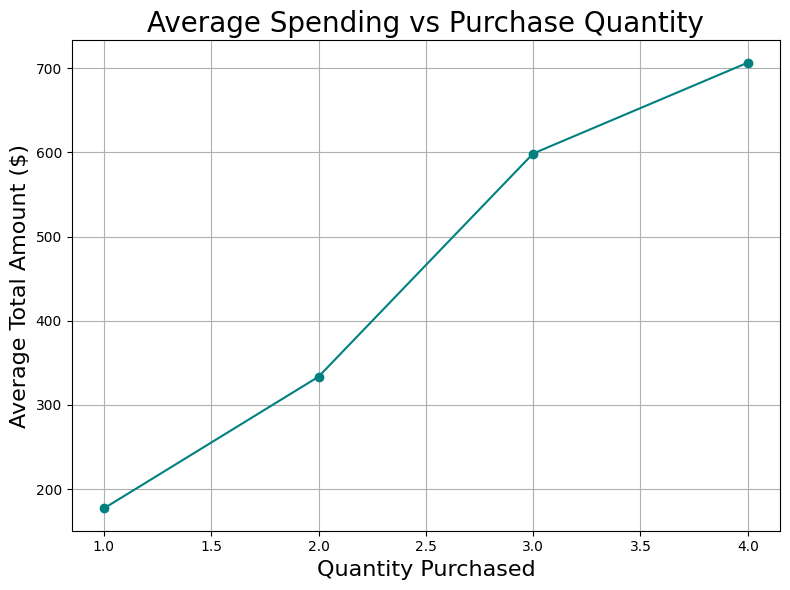

In [ ]:

plt.figure(figsize=(8, 6))

plt.plot(quantity_price.index, quantity_price.values, marker='o', linestyle='-', color='teal')

plt.title('Average Spending vs Purchase Quantity', fontsize=20)
plt.xlabel('Quantity Purchased', fontsize=16)
plt.ylabel('Average Total Amount ($)', fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

# Profitability by Product Category (High Price × High Quantity)

In [ ]:
category_profit = retail.groupby('Category').apply(
    lambda x: (x['Price per Unit'] * x['Quantity']).sum()
)

# Optional: sort descending to see top categories
category_profit = category_profit.sort_values(ascending=False)

print(category_profit)


Category
Electronics    156905
Clothing       155580
Beauty         143515
dtype: int64


/tmp/ipython-input-3851459082.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  category_profit = retail.groupby('Category').apply(


# Age Distribution Analysis (Histogram)

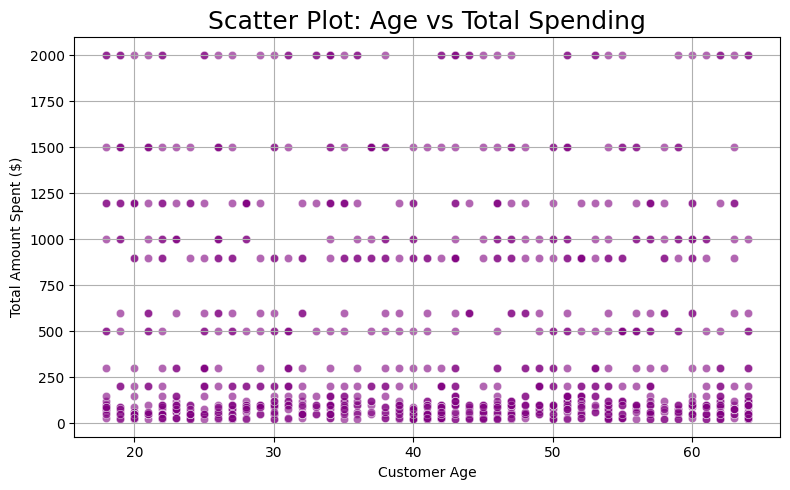

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=retail, x='Age', y='Total Amount', alpha=0.6, color='purple')

plt.title('Scatter Plot: Age vs Total Spending', fontsize=18)
plt.xlabel('Customer Age')
plt.ylabel('Total Amount Spent ($)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Correlation Heatmap of Key Metrics (Age, Quantity, Price, Total Amount)

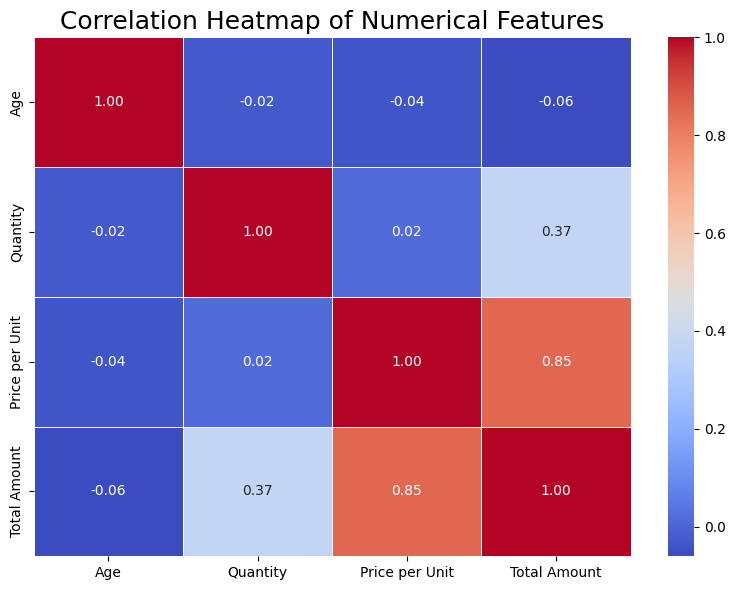

In [ ]:
numerical_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
correlation_matrix = retail[numerical_cols].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)

plt.title('Correlation Heatmap of Numerical Features', fontsize=18)
plt.tight_layout()
plt.show()